# Pareto conditional analysis — whole-cell `top1_unmet_1.0` — 2026-09-01

**Data:** `pareto_all/whole_cell_unmet_need_v5_v7.xlsx`, all 7 sheets
(`v5_1, v5_2, v5_3, v5_4, v7, v7_high_toya, relationship_kd`) combined into one
dataset. Unlike `20260804_pareto_conditional_analysis.ipynb`'s FBA-only
`pareto_results.csv` (one row per sampled weight combo, `obj_homeo`/`toya_r_squared`
computed by a single LP solve), this workbook holds **real whole-cell simulation**
results pulled from Sherlock — one row per weight combo, with the identity and
magnitude of the top-3 worst-unmet metabolites (`top{1,2,3}_metabolite_<frac>` /
`top{1,2,3}_unmet_<frac>`) at each `fraction_kinetic_target` level tested.

This notebook mirrors that reference notebook's methodology — Random Forest
importance, Pearson correlation, scatter grids sorted by \|r\|, and an interactive
Altair brushing dashboard — applied to `top1_unmet_1.0` (the no-knockdown baseline)
as the response variable.

**Up front finding that shapes this whole analysis:** the single worst-unmet
metabolite at baseline only ever takes on **3 distinct identities** across the
combined dataset, two of which are near-constant "wall values" with almost no
real spread. So this notebook runs two analyses: the full pooled data (with that
confound made explicit), and a **reconstructed C6[p]-unmet-need analysis across
essentially all rows** (not just the ones where C6[p] happens to be top1) — see
the dedicated sections below for why the naive "condition on C6[p] winning"
approach would have introduced survivorship bias, and how it's corrected here.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.ensemble import RandomForestRegressor

## Load data

Load all 7 sheets, tag each row with its source sheet, and deduplicate exact/
near-exact weight-combo rows that appear in more than one sheet (rounding to 9
decimal places to avoid float-precision false negatives).

The raw column names embed the fraction value with a literal decimal point
(e.g. `top1_metabolite_1.0`) — Vega-Lite/Altair treats dots in field names as
nested-property access, which silently breaks any chart encoding that uses them.
So immediately after loading, the fraction=1.0 columns actually used in this
notebook are renamed to remove the dot (e.g. `top1_metabolite_1.0` ->
`top1_metabolite`).

In [33]:
XLSX_PATH = "pareto_all/whole_cell_unmet_need_sep_v3.xlsx"
LAMBDA_COLS = ["lambda_hom", "lambda_sec", "lambda_eff", "lambda_kin", "lambda_div"]

xls = pd.ExcelFile(XLSX_PATH)
frames = []
for sheet in xls.sheet_names:
    d = pd.read_excel(XLSX_PATH, sheet_name=sheet)
    d["source"] = sheet
    frames.append(d)
df_raw = pd.concat(frames, ignore_index=True, sort=False)

dedup_key = df_raw[LAMBDA_COLS].round(9).apply(tuple, axis=1)
dup_mask = dedup_key.duplicated(keep="first")
print(f"Loaded {len(df_raw)} rows from {len(xls.sheet_names)} sheets: {xls.sheet_names}")
print(f"Dropping {dup_mask.sum()} exact/near-exact duplicate weight combos (kept first occurrence):")
print(df_raw.loc[dup_mask, "source"].value_counts())
df = df_raw.loc[~dup_mask].reset_index(drop=True)
print(f"{len(df)} unique weight combos after dedup")

# Dot-free renames for the fraction=1.0 columns used below (see markdown above
# for why this matters for Altair).
RENAME_MAP = {}
for i in (1, 2, 3):
    RENAME_MAP[f"top{i}_metabolite_1.0"] = f"top{i}_metabolite"
    RENAME_MAP[f"top{i}_unmet_1.0"] = f"top{i}_unmet"
df = df.rename(columns=RENAME_MAP)
df.head()

Loaded 1000 rows from 1 sheets: ['sep_v3']
Dropping 0 exact/near-exact duplicate weight combos (kept first occurrence):
Series([], Name: count, dtype: int64)
1000 unique weight combos after dedup


,Index,lambda_hom,lambda_kin,lambda_eff,lambda_sec,lambda_div,obj_homeo_1.0,top1_metabolite,top1_unmet,top2_metabolite,...,top3_metabolite,top3_unmet,obj_homeo_0.8,top1_metabolite_0.8,top1_unmet_0.8,top2_metabolite_0.8,top2_unmet_0.8,top3_metabolite_0.8,top3_unmet_0.8,source
0,8415,0.060015,0.000101,8.716000e-07,0.000128,0.007059,3.936685e-13,C6[p],9376.305569,THIAMINE-PYROPHOSPHATE[c],...,SIROHEME[c],1.192144,0.000058,C6[p],71.503885,THIAMINE-PYROPHOSPHATE[c],9.915571,CPD-12115[c],4.380123,sep_v3
1,6802,0.060628,0.000102,9.960000e-08,0.000137,0.000382,6.808189e-13,C6[p],9376.305101,THIAMINE-PYROPHOSPHATE[c],...,SIROHEME[c],1.192144,0.000058,C6[p],71.502640,THIAMINE-PYROPHOSPHATE[c],9.915571,CPD-12115[c],4.683941,sep_v3
2,9338,0.062326,0.000103,1.286000e-07,0.000139,0.000125,1.256439e-12,THIAMINE-PYROPHOSPHATE[c],9.915570,CPD-12115[c],...,REDUCED-MENAQUINONE[c],3.586408,0.000058,UDP-GLUCURONATE[c],79025.178470,PROPIONYL-COA[c],20.087248,THIAMINE-PYROPHOSPHATE[c],7.834192,sep_v3
3,6871,0.063342,0.000105,3.969000e-07,0.000139,0.000468,1.315184e-12,THIAMINE-PYROPHOSPHATE[c],9.915571,CPD-12115[c],...,REDUCED-MENAQUINONE[c],3.586408,0.000058,THIAMINE-PYROPHOSPHATE[c],9.915571,CPD-12115[c],4.685238,REDUCED-MENAQUINONE[c],3.586408,sep_v3
4,5040,0.063382,0.000103,7.450000e-08,0.000141,0.001369,2.496026e-12,C6[p],69.643258,THIAMINE-PYROPHOSPHATE[c],...,CPD-12115[c],4.378826,0.000058,C6[p],69.643258,THIAMINE-PYROPHOSPHATE[c],9.915571,CPD-12115[c],4.378826,sep_v3


## Log-transform weights and compute pairwise ratios

Same convention as `20260804_pareto_conditional_analysis.ipynb`: all analysis in
log10 space, each ratio `ratio_<a>_<b> = log10(lambda_a) - log10(lambda_b) =
log10(lambda_a / lambda_b)`. `top1_unmet` is log-transformed since it spans
~4 orders of magnitude (7.83 to 79025.2) — no clipping needed since all values are
strictly positive (unlike `obj_homeo`, which could get arbitrarily close to 0 in
FBA-only data).

In [34]:
SHORT = {"lambda_hom": "hom", "lambda_sec": "sec", "lambda_eff": "eff",
         "lambda_kin": "kin", "lambda_div": "div", "obj_homeo_1.0": "FBA_homeo"}

for c in LAMBDA_COLS:
    df[f"log_{c}"] = np.log10(df[c])
WEIGHT_FEATURES = [f"log_{c}" for c in LAMBDA_COLS]

RATIO_FEATURES = []
for a, b in combinations(LAMBDA_COLS, 2):
    name = f"ratio_{SHORT[a]}_{SHORT[b]}"
    df[name] = df[f"log_{a}"] - df[f"log_{b}"]
    RATIO_FEATURES.append(name)

TARGET = "log_top1_unmet"
df[TARGET] = np.log10(df["top1_unmet"])  # no clip needed, all values > 0

print(f"{len(WEIGHT_FEATURES)} weight features: {WEIGHT_FEATURES}")
print(f"{len(RATIO_FEATURES)} ratio features: {RATIO_FEATURES}")

5 weight features: ['log_lambda_hom', 'log_lambda_sec', 'log_lambda_eff', 'log_lambda_kin', 'log_lambda_div']
10 ratio features: ['ratio_hom_sec', 'ratio_hom_eff', 'ratio_hom_kin', 'ratio_hom_div', 'ratio_sec_eff', 'ratio_sec_kin', 'ratio_sec_div', 'ratio_eff_kin', 'ratio_eff_div', 'ratio_kin_div']


## Random Forest importance — pooled (all rows)

Fits a Random Forest regressor per feature set for `log_top1_unmet`. Only one
target here (vs. the reference notebook's two), so 2 calls instead of 4.

Caveat: because the winning metabolite (`top1_metabolite`) takes only 3 distinct
values across this dataset (see the confound section below), treat R² here as
partly reflecting the model's ability to distinguish *which metabolite regime* a
combo falls into, not a smooth weight->unmet-need surface. `n` is also much
smaller than the reference notebook's 10,000 (252 here), so treat importances as
suggestive, not precise.

In [35]:
def rf_importance(features, target, data=None, label=None, **rf_kwargs):
    """Fit a RandomForestRegressor(features -> target) and return sorted importances."""
    data = df if data is None else data
    X = data[features].values
    y = data[target].values
    rf = RandomForestRegressor(
        n_estimators=400, max_depth=10, min_samples_leaf=5,
        random_state=0, n_jobs=-1, **rf_kwargs,
    )
    rf.fit(X, y)
    importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
    print(f"--- {label or target} (R2={rf.score(X, y):.3f}, n_features={len(features)}, n={len(data)}) ---")
    for feat, imp in importances.items():
        print(f"  {feat:<15} {imp:.3f}")
    print()
    return importances


def build_summary(features_weight, features_ratio, target, data=None):
    data = df if data is None else data
    w_imp = rf_importance(features_weight, target, data, "weights -> " + target)
    r_imp = rf_importance(features_ratio, target, data, "ratios -> " + target)
    s = pd.DataFrame({
        "feature": features_weight + features_ratio,
        "kind": ["weight"] * len(features_weight) + ["ratio"] * len(features_ratio),
    })
    s["r"] = s["feature"].map(lambda f: data[f].corr(data[target]))
    s["rf_importance"] = s["feature"].map(lambda f: (w_imp if f in features_weight else r_imp)[f])
    return s.sort_values("rf_importance", ascending=False).reset_index(drop=True)


summary = build_summary(WEIGHT_FEATURES, RATIO_FEATURES, TARGET)

--- weights -> log_top1_unmet (R2=0.377, n_features=5, n=1000) ---
  log_lambda_div  0.294
  log_lambda_eff  0.228
  log_lambda_sec  0.199
  log_lambda_kin  0.169
  log_lambda_hom  0.110

--- ratios -> log_top1_unmet (R2=0.610, n_features=10, n=1000) ---
  ratio_hom_kin   0.476
  ratio_hom_sec   0.161
  ratio_sec_kin   0.083
  ratio_eff_div   0.066
  ratio_eff_kin   0.043
  ratio_kin_div   0.036
  ratio_sec_div   0.035
  ratio_hom_eff   0.034
  ratio_sec_eff   0.034
  ratio_hom_div   0.031



## Pearson correlations — pooled

One table combining RF importance and Pearson r for every weight and ratio
against `log_top1_unmet`, sorted by importance.

In [36]:
summary

,feature,kind,r,rf_importance
0,ratio_hom_kin,ratio,-0.088113,0.475570
1,log_lambda_div,weight,0.125399,0.294165
2,log_lambda_eff,weight,-0.068252,0.227504
3,log_lambda_sec,weight,-0.095251,0.199242
4,log_lambda_kin,weight,-0.083658,0.169268
5,ratio_hom_sec,ratio,0.204263,0.161388
6,log_lambda_hom,weight,-0.085846,0.109821
7,ratio_sec_kin,ratio,-0.230177,0.083220
8,ratio_eff_div,ratio,-0.138413,0.066088
9,ratio_eff_kin,ratio,-0.007099,0.042890


## Scatter plots — pooled

Each panel plots one feature against `log_top1_unmet`, titled with its Pearson
r; panels within a grid are sorted by \|r\| so the strongest relationships come
first. Two grids (weights, ratios) instead of the reference notebook's four, since
there's one target here.

In [37]:
MUTED_BLUE = "#4C78A8"


def plot_scatter(x, y, ax=None, x_label=None, y_label=None, **kwargs):
    """Scatter already-computed x/y, titled with their Pearson r."""
    ax = ax or plt.gca()
    x_label = x_label or getattr(x, "name", None) or "x"
    y_label = y_label or getattr(y, "name", None) or "y"
    ax.scatter(x, y, s=10, alpha=0.35, color=MUTED_BLUE, edgecolors="none", **kwargs)
    ax.set_xlabel(x_label, fontsize=9)
    ax.set_ylabel(y_label, fontsize=9)
    r = pd.Series(np.asarray(x)).corr(pd.Series(np.asarray(y)))
    ax.set_title(f"r = {r:+.3f}", fontsize=10)
    return ax


def plot_feature_grid(features, target, target_label, data=None, n_cols=5, figsize_per=(3.2, 2.8)):
    """Grid of plot_scatter panels, one per feature, sorted by |r| with target."""
    data = df if data is None else data
    ordered = sorted(features, key=lambda f: -abs(data[f].corr(data[target])))
    n_rows = int(np.ceil(len(ordered) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(figsize_per[0] * n_cols, figsize_per[1] * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, feat in zip(axes, ordered):
        plot_scatter(data[feat], data[target], ax=ax, x_label=feat, y_label=target_label)
    for ax in axes[len(ordered):]:
        ax.set_visible(False)
    fig.suptitle(f"{target_label} vs. features, sorted by |r|", fontsize=13, y=1.02)
    fig.tight_layout()
    plt.show()

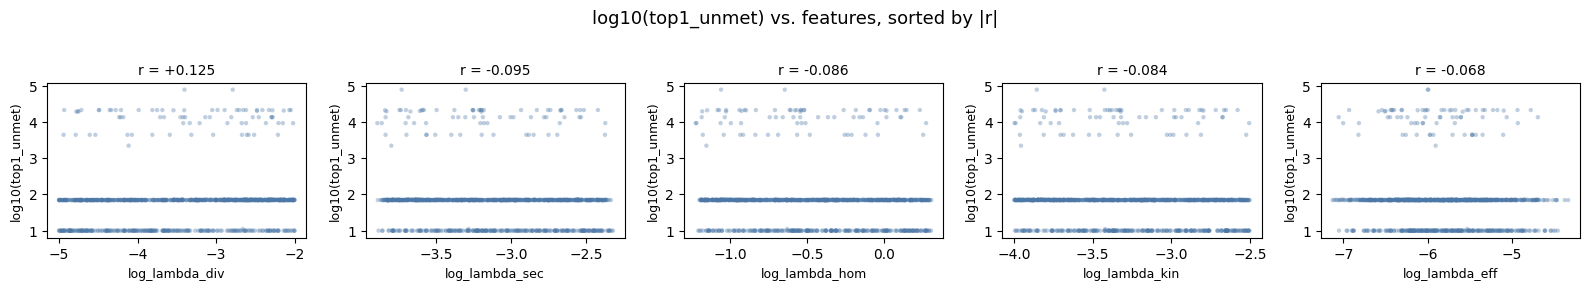

In [38]:
plot_feature_grid(WEIGHT_FEATURES, TARGET, "log10(top1_unmet)")

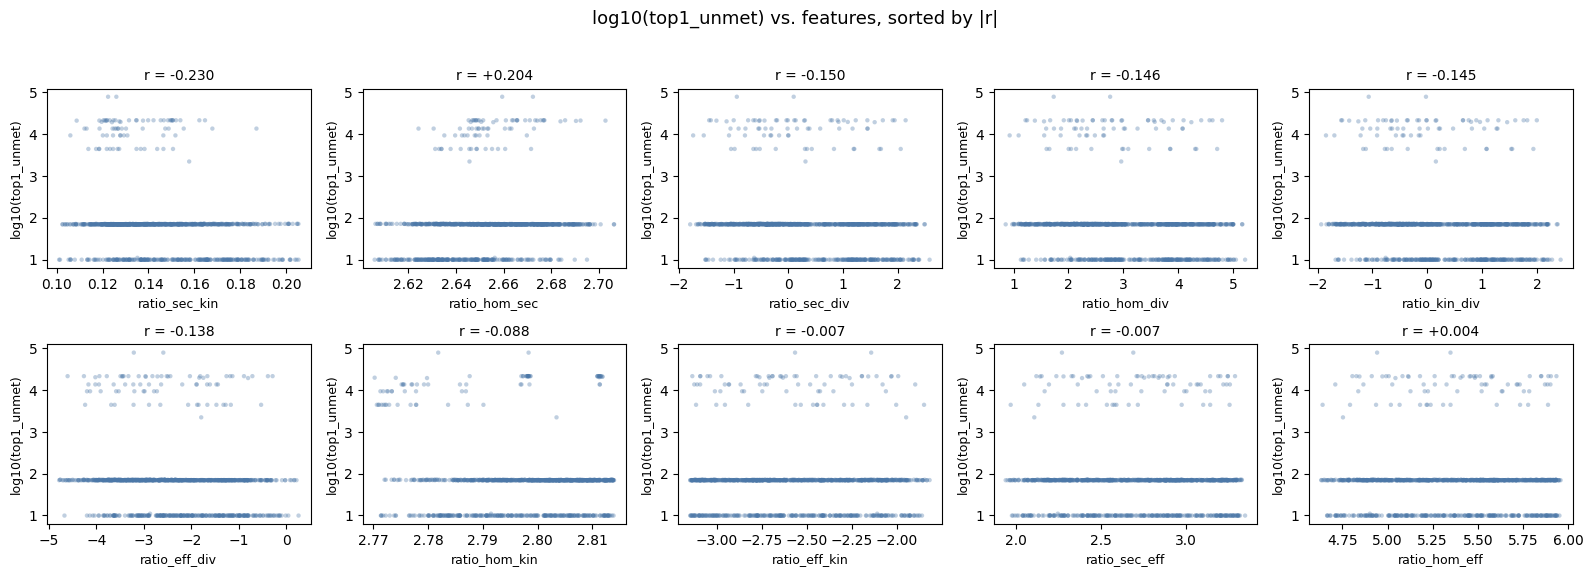

In [39]:
plot_feature_grid(RATIO_FEATURES, TARGET, "log10(top1_unmet)")

## Metabolite-identity confound

`top1_unmet` is *whichever* of ~172 homeostatic metabolites happens to have the
single largest unmet need for a given weight combo — not a smooth aggregate like
`obj_homeo`. Prior investigation in this project found that specific metabolites
recur at exact, repeated numeric values across many unrelated weight combos (a
"wall value" tied to network-structural bottlenecks or near-zero-count ratio
artifacts, largely independent of weight tuning). Check how dominant that effect
is here before trusting the pooled RF/Pearson results above.

In [40]:
METABOLITE_COLORS = {
    "THIAMINE-PYROPHOSPHATE[c]": "#4C78A8",
    "C6[p]": "#F58518",
    "UDP-GLUCURONATE[c]": "#54A24B",
}

metab_summary = (
    df.groupby("top1_metabolite")["top1_unmet"]
    .agg(n="count", mean="mean", median="median", std="std", min="min", max="max")
    .sort_values("n", ascending=False)
)
print(metab_summary)
print()
print("Distinct values (rounded to 4 decimals) per metabolite -- low counts here mean")
print("most occurrences are the literal same repeated 'wall' value:")
print(df.groupby("top1_metabolite")["top1_unmet"].apply(lambda s: s.round(4).nunique()))
metab_summary

                             n          mean        median           std  \
top1_metabolite                                                            
C6[p]                      743   1493.627933     69.643329  4.793676e+03   
THIAMINE-PYROPHOSPHATE[c]  255      9.917020      9.915570  4.847969e-03   
UDP-GLUCURONATE[c]           2  79025.178470  79025.178470  2.716496e-09   

                                    min           max  
top1_metabolite                                        
C6[p]                         10.075829  21581.969033  
THIAMINE-PYROPHOSPHATE[c]      9.915569      9.933171  
UDP-GLUCURONATE[c]         79025.178470  79025.178470  

Distinct values (rounded to 4 decimals) per metabolite -- low counts here mean
most occurrences are the literal same repeated 'wall' value:
top1_metabolite
C6[p]                        45
THIAMINE-PYROPHOSPHATE[c]     2
UDP-GLUCURONATE[c]            1
Name: top1_unmet, dtype: int64


,n,mean,median,std,min,max
top1_metabolite,,,,,,
C6[p],743,1493.627933,69.643329,4.793676e+03,10.075829,21581.969033
THIAMINE-PYROPHOSPHATE[c],255,9.917020,9.915570,4.847969e-03,9.915569,9.933171
UDP-GLUCURONATE[c],2,79025.178470,79025.178470,2.716496e-09,79025.178470,79025.178470


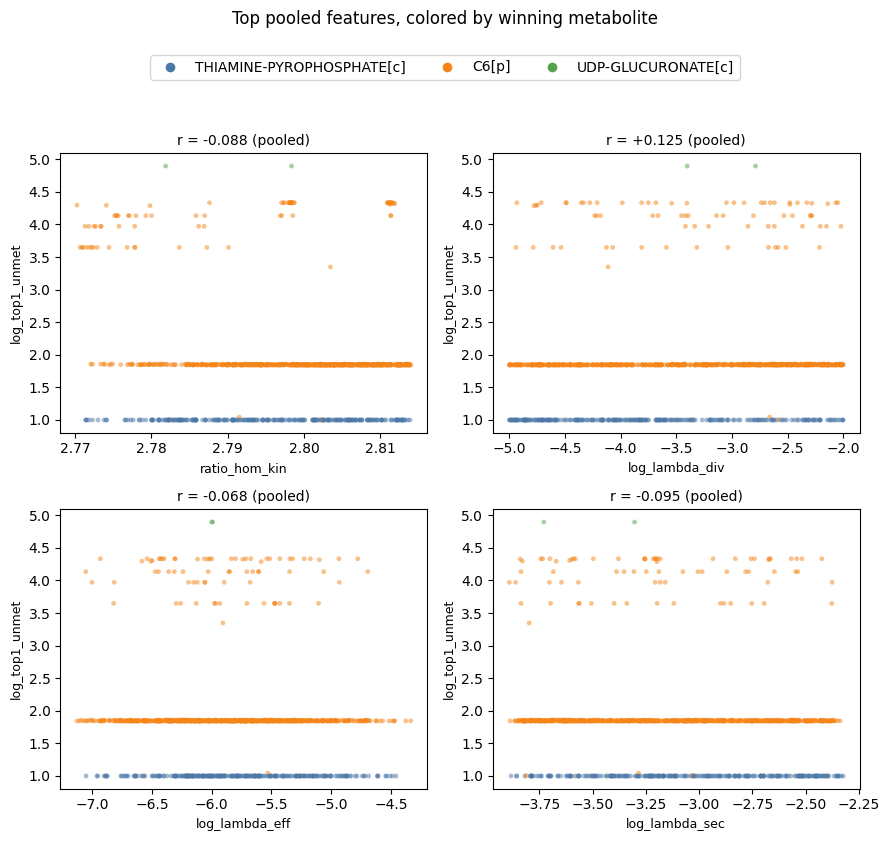

In [41]:
top_features = summary["feature"].head(4).tolist()
n_cols = 2
n_rows = int(np.ceil(len(top_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.8 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, feat in zip(axes, top_features):
    colors = df["top1_metabolite"].map(METABOLITE_COLORS).fillna(MUTED_BLUE)
    ax.scatter(df[feat], df[TARGET], s=12, alpha=0.5, c=colors, edgecolors="none")
    r = df[feat].corr(df[TARGET])
    ax.set_xlabel(feat, fontsize=9)
    ax.set_ylabel(TARGET, fontsize=9)
    ax.set_title(f"r = {r:+.3f} (pooled)", fontsize=10)
for ax in axes[len(top_features):]:
    ax.set_visible(False)
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=8, label=m)
           for m, c in METABOLITE_COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.05))
fig.suptitle("Top pooled features, colored by winning metabolite", fontsize=12, y=1.1)
fig.tight_layout()
plt.show()

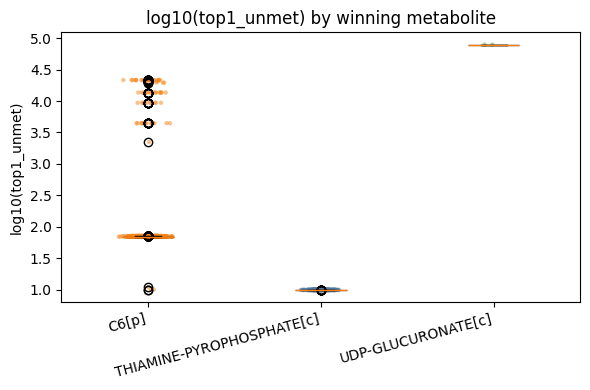

In [42]:
order = metab_summary.index.tolist()
fig, ax = plt.subplots(figsize=(6, 4))
data_by_metab = [df.loc[df["top1_metabolite"] == m, TARGET].values for m in order]
bp = ax.boxplot(data_by_metab, tick_labels=order, patch_artist=True)
for patch, m in zip(bp["boxes"], order):
    patch.set_facecolor(METABOLITE_COLORS.get(m, MUTED_BLUE))
    patch.set_alpha(0.6)
for m, vals in zip(order, data_by_metab):
    x = np.random.normal(loc=order.index(m) + 1, scale=0.05, size=len(vals))
    ax.scatter(x, vals, s=10, alpha=0.5, color=METABOLITE_COLORS.get(m, MUTED_BLUE), edgecolors="none")
ax.set_ylabel("log10(top1_unmet)")
ax.set_title("log10(top1_unmet) by winning metabolite")
plt.xticks(rotation=15, ha="right")
fig.tight_layout()
plt.show()

## C6[p] unmet-need across (almost) all weight combos — survivorship-bias correction

An earlier version of this notebook restricted this section to just the rows
where C6[p] happens to be `top1` (107 rows) and asked "what predicts a *higher*
C6[p] value within that subset." That conditions on an outcome (whether C6[p]
wins at all) and throws away exactly the rows that show what keeps C6[p] *low* —
i.e. every row where `THIAMINE-PYROPHOSPHATE[c]` or `UDP-GLUCURONATE[c]` won
instead, which are the "success" cases for C6[p] specifically. That's a real
survivorship bias.

Checking the raw per-experiment CSVs (which record top1/2/3, not just top1):
C6[p] is directly observed (ranked 1st, 2nd, or 3rd worst) in **116 of 255** rows
at `fraction_kinetic_target=1.0`. For the other 139 rows, C6[p] didn't rank in the
top 3 at all — but we still know it's *below* that row's top-3 threshold, which is
small (median ~3.6, max ~9.1) — genuinely negligible compared to the observed
"C6[p]-is-bad" values (up to 21582). So those rows are imputed with that row's
top-3 value as a conservative upper-bound proxy, giving full coverage across
(almost) the entire dataset — including both the weight combos that keep C6[p]
low and the ones that make it catastrophic, which is what actually answers "what
weights get us there."

This uses `top1/2/3_metabolite`/`top1/2/3_unmet` at `fraction_kinetic_target=1.0`,
which required extending `build_whole_cell_unmet_need_excel.py` to pivot top2/top3
into the workbook too (it previously only kept top1).

In [43]:
def reconstruct_unmet(row, metabolite):
    for i in (1, 2, 3):
        if row.get(f"top{i}_metabolite") == metabolite:
            return row.get(f"top{i}_unmet")
    return row.get("top3_unmet")  # not in top 3 -> conservative upper-bound proxy


def found_rank(row, metabolite):
    for i in (1, 2, 3):
        if row.get(f"top{i}_metabolite") == metabolite:
            return i
    return None


df["c6p_unmet"] = df.apply(lambda r: reconstruct_unmet(r, "C6[p]"), axis=1)
df["c6p_rank"] = df.apply(lambda r: found_rank(r, "C6[p]"), axis=1)

n_found = int(df["c6p_rank"].notna().sum())
n_missing = int(df["c6p_rank"].isna().sum())
missing_proxy = df.loc[df["c6p_rank"].isna(), "top3_unmet"]
print(f"C6[p] directly observed in top1/2/3 for {n_found}/{len(df)} rows.")
print(f"For the remaining {n_missing} rows, using that row's top3_unmet as a proxy "
      f"(median {missing_proxy.median():.2f}, max {missing_proxy.max():.2f}).")
print(f"c6p_rank value counts:\n{df['c6p_rank'].value_counts(dropna=False)}")

df["log_c6p_unmet"] = np.log10(df["c6p_unmet"])
TARGET_C6 = "log_c6p_unmet"

summary_c6_full = build_summary(WEIGHT_FEATURES, RATIO_FEATURES, TARGET_C6)
summary_c6_full

C6[p] directly observed in top1/2/3 for 875/1000 rows.
For the remaining 125 rows, using that row's top3_unmet as a proxy (median 3.59, max 7.83).
c6p_rank value counts:
c6p_rank
1.0    743
2.0    132
NaN    125
Name: count, dtype: int64
--- weights -> log_c6p_unmet (R2=0.370, n_features=5, n=1000) ---
  log_lambda_div  0.280
  log_lambda_eff  0.239
  log_lambda_sec  0.203
  log_lambda_kin  0.163
  log_lambda_hom  0.114

--- ratios -> log_c6p_unmet (R2=0.608, n_features=10, n=1000) ---
  ratio_hom_kin   0.457
  ratio_hom_sec   0.155
  ratio_sec_kin   0.090
  ratio_eff_div   0.066
  ratio_eff_kin   0.047
  ratio_hom_eff   0.042
  ratio_sec_div   0.038
  ratio_sec_eff   0.037
  ratio_kin_div   0.037
  ratio_hom_div   0.031



,feature,kind,r,rf_importance
0,ratio_hom_kin,ratio,-0.065522,0.457416
1,log_lambda_div,weight,0.107493,0.280053
2,log_lambda_eff,weight,-0.061609,0.239396
3,log_lambda_sec,weight,-0.082132,0.203090
4,log_lambda_kin,weight,-0.071277,0.162975
5,ratio_hom_sec,ratio,0.200094,0.155047
6,log_lambda_hom,weight,-0.072902,0.114484
7,ratio_sec_kin,ratio,-0.215290,0.090350
8,ratio_eff_div,ratio,-0.120248,0.066045
9,ratio_eff_kin,ratio,-0.011494,0.046805


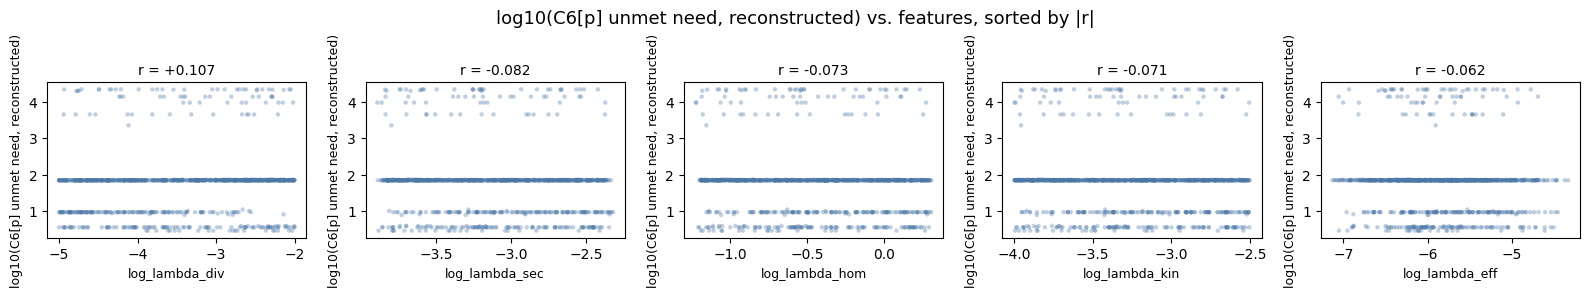

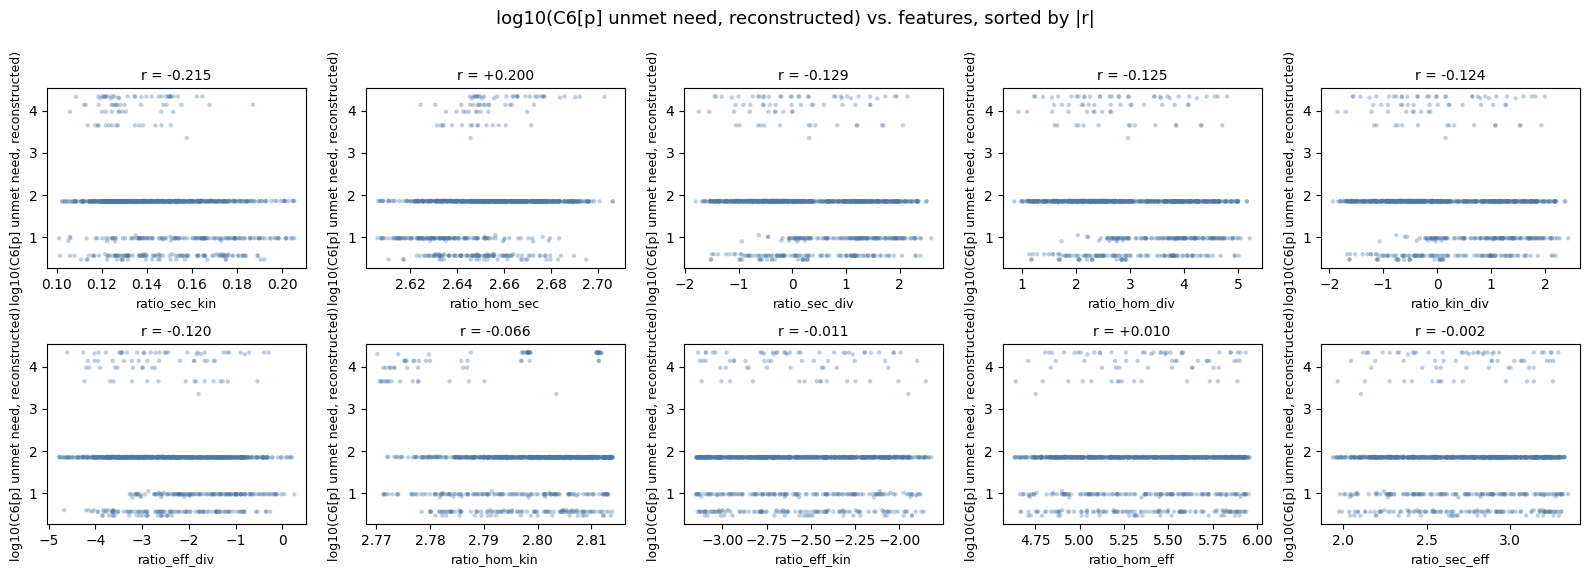

In [44]:
plot_feature_grid(WEIGHT_FEATURES, TARGET_C6, "log10(C6[p] unmet need, reconstructed)")
plot_feature_grid(RATIO_FEATURES, TARGET_C6, "log10(C6[p] unmet need, reconstructed)")

## Interactive Altair dashboard

The reference notebook colors points by the *other* continuous response
(`toya_r_squared`) while brushing on the first — there's no second continuous
response here, so the foreground layer is colored by `top1_metabolite`
(categorical) instead, directly visualizing the confound while brushing. Ratio
panels are chosen programmatically from the pooled `summary` table's top-ranked
ratios rather than hardcoded, since it isn't known in advance which will rank
highest for this new target.

(Field names used below are all dot-free, per the fix described in the "Load
data" section — Altair/Vega-Lite silently fails to render points whose encoding
references a field name containing a literal `.`.)

In [45]:
import altair as alt

interval = alt.selection_interval()
tooltip = ["ratio_hom_eff", "ratio_hom_kin", "top1_unmet", "top1_metabolite", "c6p_unmet", "source", "lambda_hom", "lambda_kin"]

def make_layered_chart(x_field, title, y_field=TARGET):
    base = alt.Chart(df).mark_circle(size=60, opacity=0.5)
    background = base.encode(x=alt.X(x_field), y=alt.Y(y_field), color=alt.value("lightgray"))
    foreground = base.encode(
        x=alt.X(x_field),
        y=alt.Y(y_field),
        color=alt.Color(
            "top1_metabolite:N",
            scale=alt.Scale(domain=list(METABOLITE_COLORS), range=list(METABOLITE_COLORS.values())),
            legend=alt.Legend(title="Winning metabolite"),
        ),
        tooltip=tooltip,
    ).transform_filter(interval)
    return (background + foreground).properties(width=400, height=300, title=title).add_params(interval)


top_ratios = summary[summary["kind"] == "ratio"].sort_values("rf_importance", ascending=False)["feature"].head(4).tolist()
print(f"Top 4 ratios by pooled RF importance: {top_ratios}")

chart_1 = make_layered_chart(top_ratios[0], f"Interactive Scatter: {top_ratios[0]} vs {TARGET}")
chart_2 = make_layered_chart(top_ratios[1], f"Interactive Scatter: {top_ratios[1]} vs {TARGET}")
chart_3 = make_layered_chart(top_ratios[2], f"Interactive Scatter: {top_ratios[2]} vs {TARGET}")
chart_4 = make_layered_chart(top_ratios[3], f"Interactive Scatter: {top_ratios[3]} vs {TARGET}")

Top 4 ratios by pooled RF importance: ['ratio_hom_kin', 'ratio_hom_sec', 'ratio_sec_kin', 'ratio_eff_div']


In [46]:
density = (
    alt.Chart(df)
    .transform_filter(interval)
    .mark_bar(opacity=0.4)
    .encode(
        x=alt.X("top1_metabolite:N", title="Winning metabolite", scale=alt.Scale(domain=list(METABOLITE_COLORS))),
        y=alt.Y("count()", title="Count"),
        color=alt.Color(
            "top1_metabolite:N",
            scale=alt.Scale(domain=list(METABOLITE_COLORS), range=list(METABOLITE_COLORS.values())),
            legend=None,
        ),
        tooltip=[alt.Tooltip("top1_metabolite:N", title="Metabolite"), alt.Tooltip("count()", title="Count")],
    )
    .properties(title="Winning metabolite in brushed selection", width=300, height=300)
)

In [47]:
import os

scatter_chart = alt.hconcat(chart_1, chart_2) & alt.hconcat(chart_3, chart_4)
chart = scatter_chart | density
alt.data_transformers.enable("vegafusion")
alt.renderers.enable('browser')
chart.show()

OUT_DIR = "pareto_all/pareto_conditional_analysis_whole_cell"
os.makedirs(OUT_DIR, exist_ok=True)
out = os.path.join(OUT_DIR, "ratio_pairwise_analysis_top1_unmet.html")
chart.save(out)
print(f"Saved: {out}")

Saved: pareto_all/pareto_conditional_analysis_whole_cell/ratio_pairwise_analysis_top1_unmet.html


In [48]:
# Facet by source sheet -- check whether patterns are driven by one experiment
# batch's sampling design rather than genuinely conditional on the weights.
facet_chart = (
    alt.Chart(df)
    .mark_circle(size=40, opacity=0.5)
    .encode(
        x=alt.X(top_ratios[0]),
        y=alt.Y(TARGET),
        color=alt.Color(
            "top1_metabolite:N",
            scale=alt.Scale(domain=list(METABOLITE_COLORS), range=list(METABOLITE_COLORS.values())),
            legend=alt.Legend(title="Winning metabolite"),
        ),
        tooltip=tooltip,
    )
    .properties(width=220, height=180)
    .facet("source:N", columns=4, title=f"{top_ratios[0]} vs {TARGET}, faceted by source sheet")
)
facet_chart.show()
out2 = os.path.join(OUT_DIR, "ratio_pairwise_analysis_top1_unmet_by_source.html")
facet_chart.save(out2)
print(f"Saved: {out2}")

Saved: pareto_all/pareto_conditional_analysis_whole_cell/ratio_pairwise_analysis_top1_unmet_by_source.html


## Added analysis for FBA homeostatic objective to WC top 1 unmet need

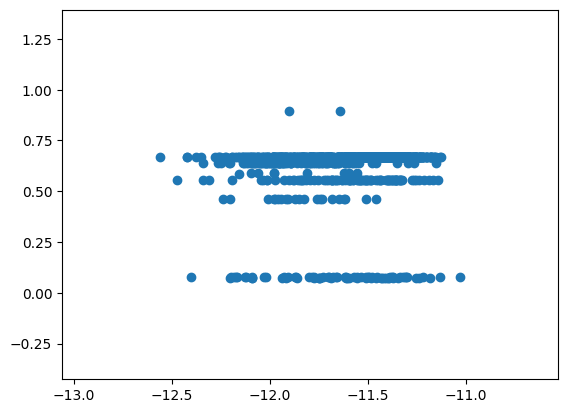

In [59]:
%matplotlib inline

x = np.log10(df_raw["obj_homeo_1.0"])
y = np.log10(df_raw["top3_unmet_1.0"])

plt.figure()
plt.plot(x,y, 'o')
plt.ylim(min(y)-0.5, max(y)+0.5)
plt.xlim(min(x)-0.5, max(x)+0.5)
plt.show()

## Summary

**What to look for above:**
- Compare pooled `rf_importance` for weights vs. ratios — expect ratios to
  dominate, mirroring the reference notebook's `obj_homeo` finding, *if* the
  wall-value/metabolite-regime structure doesn't swamp it.
- **Headline caveat on the pooled results**: any weight/ratio "importance" there
  is confounded by (and likely partly *is*) predicting which of 3 metabolites
  wins the "worst-unmet" slot for a given combo.
- **The reconstructed C6[p]-unmet-need analysis (section above) is the
  survivorship-bias-corrected version of the original question** — it uses
  (almost) all 252 rows rather than just the 107/110 where C6[p] happened to be
  top1, so its RF importances/correlations are the more trustworthy answer to
  "what weights predict C6[p]'s unmet need magnitude" specifically. Compare its
  top features against the pooled `top1_unmet` table to see how much the pooled
  result was really just detecting the regime split rather than a C6[p]-specific
  signal.

**Possible future extensions (not implemented here):** the same pattern could be
applied to the other `fraction_kinetic_target` levels (`0.8, 0.6, 0.5, 0.4, 0.1`),
or to a cross-fraction delta/response-magnitude metric, to analyze how weight
tuning relates to the *knockdown response* rather than just the baseline.